In [3]:
pip install --upgrade pip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 6.5 MB/s  0:00:00 eta 0:00:01
  Attempting uninstall: pip
    Found existing installation: pip 25.3
    Uninstalling pip-25.3:
      Successfully uninstalled pip-25.3
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install pandas numpy matplotlib seaborn scikit-learn catboost optuna pytorch-tabnet torch


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /usr/local/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install numpy==2.3.0 shap


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: /usr/local/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
#Catboost
import pandas as pd
import numpy as np
import optuna

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, f1_score
from sklearn.utils import shuffle
from catboost import CatBoostClassifier

# Load datasets

hep = pd.read_csv("/Users/macbook/Desktop/Final_Year_Project/Datasets/HepatitisCdata.csv")
liver_train = pd.read_csv("/Users/macbook/Desktop/Final_Year_Project/Datasets/Liver Patient Dataset (LPD)_train (1) (1) (1).csv")
indian_test = pd.read_csv("/Users/macbook/Desktop/Final_Year_Project/Datasets/indian_liver_patient.csv")

# Clean column names
def clean_cols(df):
    df.columns = df.columns.str.strip().str.replace(" ", "_")
    return df

hep = clean_cols(hep)
liver_train = clean_cols(liver_train)
indian_test = clean_cols(indian_test)

# Fix naming mismatch
hep.rename(columns={'Total_Proteins': 'Total_Protiens'}, inplace=True)
indian_test.rename(columns={'Total_Proteins': 'Total_Protiens'}, inplace=True)

# Feature set
common_features = [
    "Age", "Total_Bilirubin", "Albumin",
    "ALT", "AST", "ALP", "Total_Protiens"
]

# Targets
hep["target"] = (hep["Target"] != "0=Blood Donor").astype(int)
liver_train["target"] = liver_train["Result"].apply(lambda x: 1 if x == 1 else 0)
indian_test["target"] = indian_test["Dataset"].apply(lambda x: 1 if x == 1 else 0)

# Select features
hep = hep[common_features + ["target"]]
liver_train = liver_train[common_features + ["target"]]
indian_test = indian_test[common_features + ["target"]]

# Dataset-wise normalization
def normalize(df):
    scaler = StandardScaler()
    df[common_features] = scaler.fit_transform(df[common_features])
    return df

hep = normalize(hep)
liver_train = normalize(liver_train)
indian_test = normalize(indian_test)

# Merge training datasets
train_data = pd.concat([hep, liver_train], axis=0)
train_data = shuffle(train_data, random_state=42)
train_data = train_data.drop_duplicates()

print("Training rows:", len(train_data))

# Split train/validation
X = train_data.drop("target", axis=1)
y = train_data["target"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)
# Imputation
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(indian_test.drop("target", axis=1))
y_test = indian_test["target"]

# Optuna tuning
def objective(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 300, 900),
        "depth": trial.suggest_int("depth", 4, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.15),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 2, 8),
        "loss_function": "Logloss",
        "eval_metric": "AUC",
        "verbose": 0
    }

    model = CatBoostClassifier(**params)
    model.fit(X_train, y_train)

    probs = model.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, probs)

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=20)

best_params = study.best_params
print("Best Params:", best_params)

# Final training
X_full = np.vstack([X_train, X_val])
y_full = np.concatenate([y_train, y_val])

model = CatBoostClassifier(
    **best_params,
    class_weights=[1, 6],
    loss_function="Logloss",
    eval_metric="AUC",
    verbose=100
)

model.fit(X_full, y_full)

# Test prediction
probs = model.predict_proba(X_test)[:, 1]

# Threshold Optimization
thresholds = np.arange(0.1, 0.9, 0.01)

best_thresh = 0.5
best_f1 = 0

for t in thresholds:
    preds = (probs > t).astype(int)
    f1 = f1_score(y_test, preds)

    if f1 > best_f1:
        best_f1 = f1
        best_thresh = t

print("\nBest Threshold:", best_thresh)
print("Best F1:", best_f1)
# Final evaluation
preds = (probs > best_thresh).astype(int)

print("\nClassification Report")
print(classification_report(y_test, preds))
print("ROC-AUC:", roc_auc_score(y_test, probs))

[I 2026-04-25 00:23:56,171] A new study created in memory with name: no-name-d62557c4-3224-449e-9445-e93d2ea3914e


Training rows: 17001


[I 2026-04-25 00:24:02,431] Trial 0 finished with value: 0.9967024397066919 and parameters: {'iterations': 782, 'depth': 8, 'learning_rate': 0.12415360040216532, 'l2_leaf_reg': 4.2532499049941075}. Best is trial 0 with value: 0.9967024397066919.
[I 2026-04-25 00:24:04,856] Trial 1 finished with value: 0.9892174657659568 and parameters: {'iterations': 624, 'depth': 4, 'learning_rate': 0.06449373798534594, 'l2_leaf_reg': 3.662216314407575}. Best is trial 0 with value: 0.9967024397066919.
[I 2026-04-25 00:24:07,579] Trial 2 finished with value: 0.9938379129167592 and parameters: {'iterations': 502, 'depth': 6, 'learning_rate': 0.05739904464991501, 'l2_leaf_reg': 7.608836499658153}. Best is trial 0 with value: 0.9967024397066919.
[I 2026-04-25 00:24:11,551] Trial 3 finished with value: 0.9962828241428578 and parameters: {'iterations': 407, 'depth': 8, 'learning_rate': 0.13949568921462116, 'l2_leaf_reg': 4.847458334548497}. Best is trial 0 with value: 0.9967024397066919.
[I 2026-04-25 00:24

Best Params: {'iterations': 650, 'depth': 7, 'learning_rate': 0.08434894663405632, 'l2_leaf_reg': 3.095132302938614}
0:	total: 6.2ms	remaining: 4.02s
100:	total: 565ms	remaining: 3.07s
200:	total: 1.06s	remaining: 2.36s
300:	total: 1.63s	remaining: 1.89s
400:	total: 2.15s	remaining: 1.33s
500:	total: 2.61s	remaining: 776ms
600:	total: 3.05s	remaining: 248ms
649:	total: 3.24s	remaining: 0us

Best Threshold: 0.6499999999999997
Best F1: 0.9541062801932367

Classification Report
              precision    recall  f1-score   support

           0       0.88      0.90      0.89       167
           1       0.96      0.95      0.95       416

    accuracy                           0.93       583
   macro avg       0.92      0.92      0.92       583
weighted avg       0.94      0.93      0.94       583

ROC-AUC: 0.9734137494242284


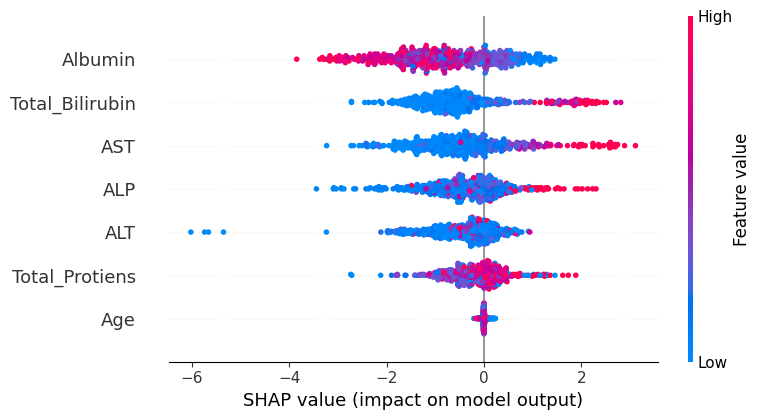

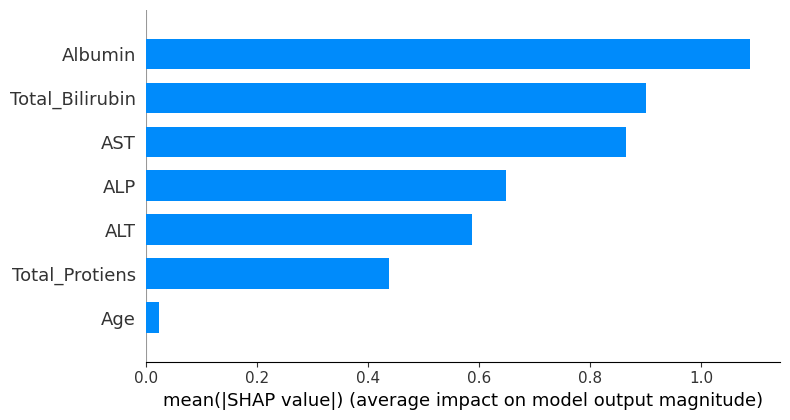

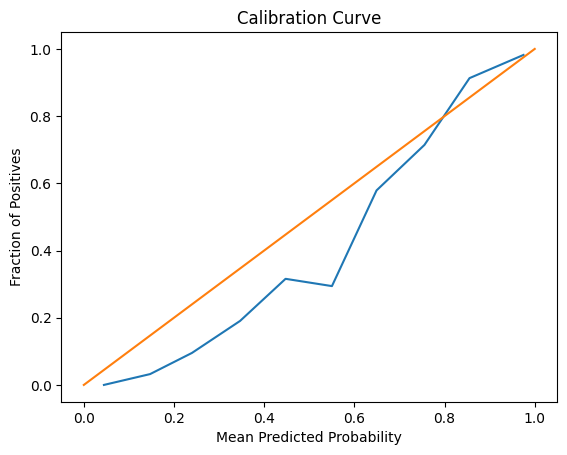

Brier Score: 0.05983711124478752


In [5]:
# SHAP EXPLANATION
import shap
import matplotlib.pyplot as plt

# Convert back to DataFrame (important for feature names)
X_test_df = pd.DataFrame(X_test, columns=common_features)

# Create SHAP explainer
explainer = shap.TreeExplainer(model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_test_df)

# Summary Plot (Global Feature Importance)
plt.figure()
shap.summary_plot(shap_values, X_test_df)

# Bar Plot (Mean Importance)
plt.figure()
shap.summary_plot(shap_values, X_test_df, plot_type="bar")

# CALIBRATION CURVE

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Compute calibration values
prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10)

# Plot calibration curve
plt.figure()
plt.plot(prob_pred, prob_true)
plt.plot([0, 1], [0, 1])
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curve")
plt.show()

# Brier Score (lower is better)
brier = brier_score_loss(y_test, probs)
print("Brier Score:", brier)